In [1]:
pip install pandas==2.2.3

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install matplotlib==3.10.0

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install seaborn==0.13.2

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd

from IPython.display import display, HTML
display(HTML("<style>.container { width:1000% !important; }</style>"))
pd.options.display.max_columns=400
pd.options.display.max_rows=8000

import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df_outages = pd.read_csv("data/outage_report_summaries.csv")
df_services = pd.read_csv("data/cloud_service_risk_ratings.csv")
# Filter first dummy record of file
df_services = df_services[df_services['service_provider'].str.contains('BAD CLOUD EXAMPLE') == False]

In [6]:
#df_outages

In [7]:
#df_services

In [8]:
df_outages1 = df_outages[df_outages['cloud_provider'].str.contains('AWS|GCP|Azure|MongoDB|IBM|Oracle') == False] # Exclude to view  not in != Oracle 
df_outages1

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output


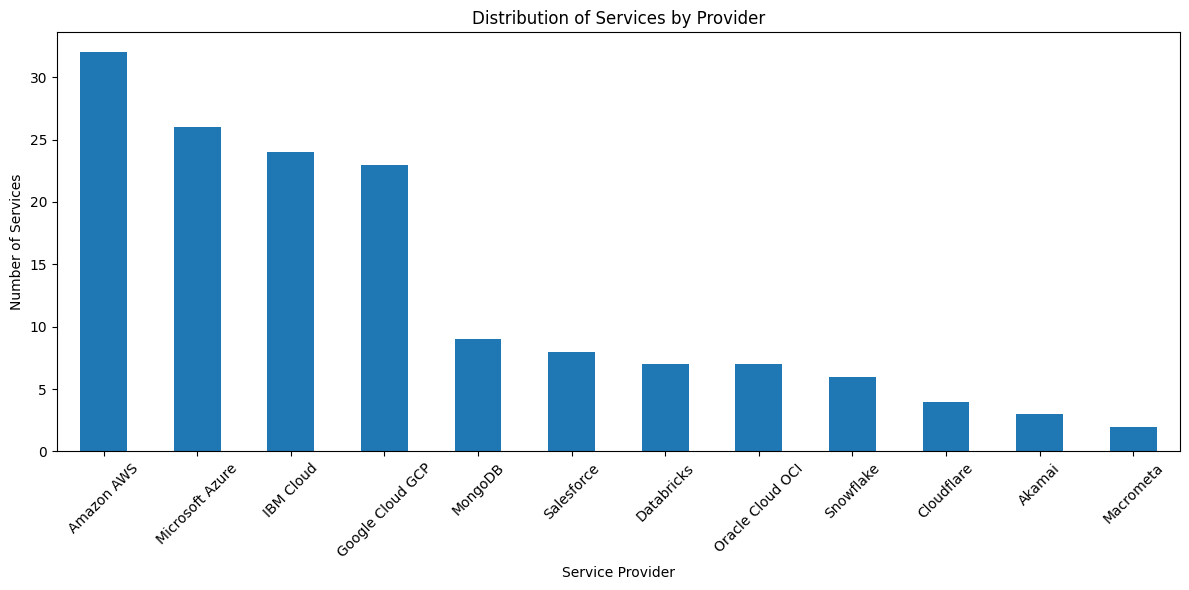

In [9]:
# 1.Service Provider Distribution:
df = df_services
plt.figure(figsize=(12, 6))
df['service_provider'].value_counts().plot(kind='bar')
plt.title('Distribution of Services by Provider')
plt.xlabel('Service Provider')
plt.ylabel('Number of Services')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

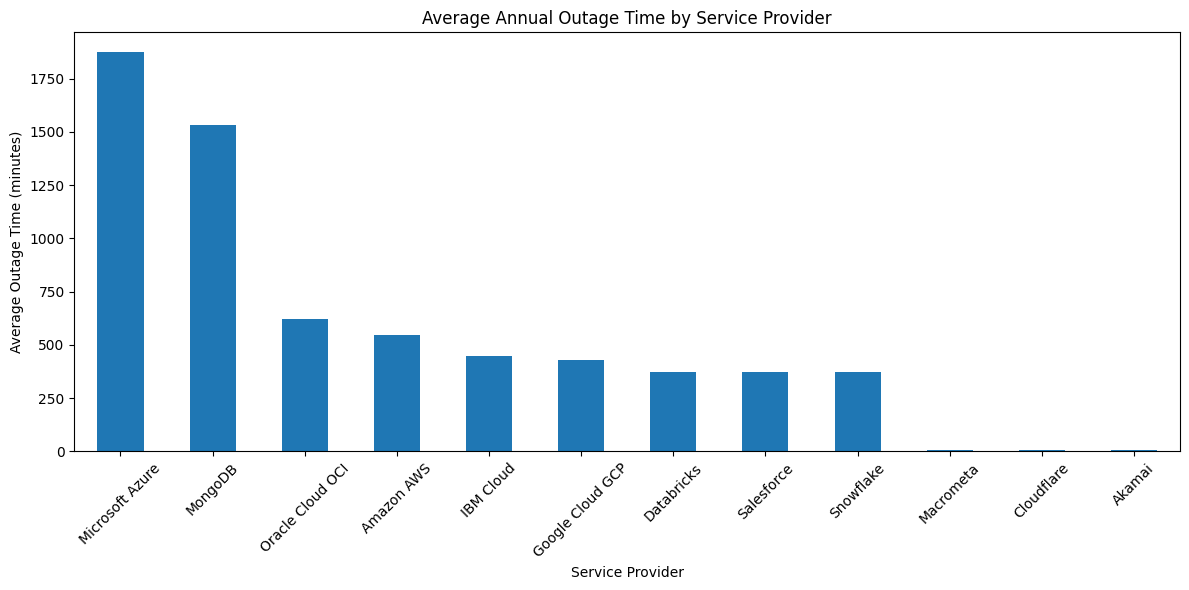

In [10]:
# 2.Average Annual Outage Time by Service Provider:
plt.figure(figsize=(12, 6))
df.groupby('service_provider')['webscraper_annual_period_service_down_per_year_in_minutes'].mean().sort_values(ascending=False).plot(kind='bar')
plt.title('Average Annual Outage Time by Service Provider')
plt.xlabel('Service Provider')
plt.ylabel('Average Outage Time (minutes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

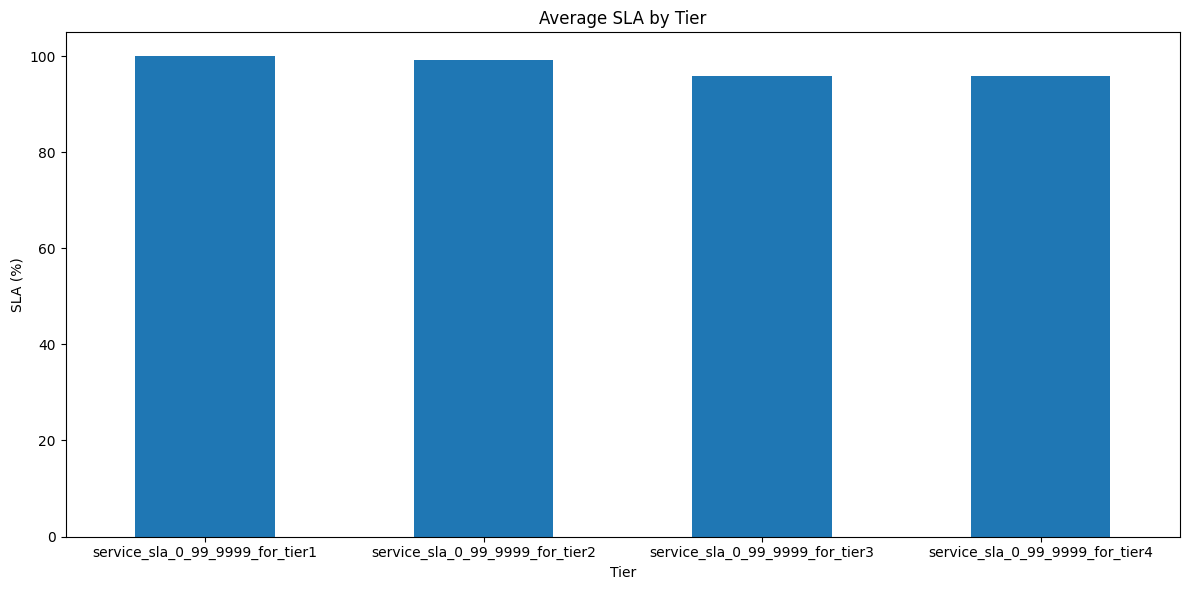

In [11]:
# 3.Service SLA Tiers Comparison:
plt.figure(figsize=(12, 6))
df[['service_sla_0_99_9999_for_tier1', 'service_sla_0_99_9999_for_tier2', 'service_sla_0_99_9999_for_tier3', 'service_sla_0_99_9999_for_tier4']].mean().plot(kind='bar')
plt.title('Average SLA by Tier')
plt.xlabel('Tier')
plt.ylabel('SLA (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

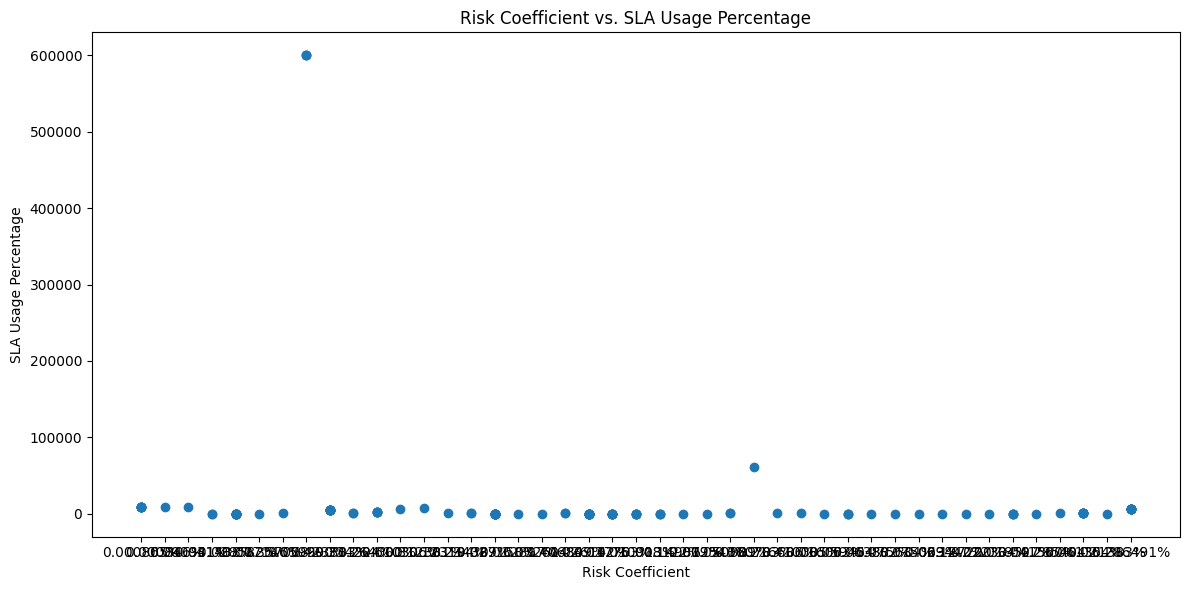

In [12]:
# 4.Risk Coefficient vs. SLA Usage Percentage:
plt.figure(figsize=(12, 6))
plt.scatter(df['riskcoef_per_service_from_gap_expected_actual_time_down'], df['service_sla_usage_percentage'])
plt.title('Risk Coefficient vs. SLA Usage Percentage')
plt.xlabel('Risk Coefficient')
plt.ylabel('SLA Usage Percentage')
plt.tight_layout()
plt.show()

In [13]:
# Global
df_outages_dedup = df_outages.drop_duplicates(subset=['outage_timestamp','source_outage_report','cloud_provider','cloud_service','regions']).sort_values(by=['outage_timestamp'],ascending=True)
df_outages_dedup.to_csv('data/new_sorted_outages_dedup.csv', index=False)

In [14]:
df_outages_dedup.describe()

,outage_timestamp,duration_minutes,resolution,mitigation_steps
count,6.048000e+03,6048.000000,0.0,0.0
mean,1.691952e+09,6669.676587,NaN,NaN
std,5.248328e+07,54913.886337,NaN,NaN
min,1.576085e+09,0.000000,NaN,NaN
25%,1.632283e+09,110.000000,NaN,NaN
50%,1.722997e+09,336.000000,NaN,NaN
75%,1.731225e+09,460.000000,NaN,NaN
max,1.741260e+09,563040.000000,NaN,NaN


In [15]:
df_outages_dedup.shape[0]

6048

In [16]:
df_outages_dedup.head(10)

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output
1088,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure CDN,global (except north america),not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
1089,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure CDN,north america,not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
1090,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,global (except north america),not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
1091,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,north america,not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
1028,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,uaecentral,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
1012,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Ams,norwayeast,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
1013,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Ams,usgovarizona,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
1014,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Ams,centralus,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
1019,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Ams,switzerlandnorth,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
1020,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Ams,japaneast,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...


In [17]:
df_outages_dedup.tail(10)

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output
2643,1.739449e+09,outages_files/Google Cloud Service Health - 20...,GCP,Google Cloud VertexAI,europe-west2,NaN,2025-02-13T12:13:00+00:00,2025-02-13T21:39:00+00:00,investigating,NaN,9 hours and 26 minutes,566,Not specified,NaN,NaN,NaN,Google GCP,NaN,Source Outage Report: outages_files/Google Clo...
2647,1.739890e+09,outages_files/Google Cloud Service Health - 20...,GCP,Google Cloud VertexAI,global,southamerica-east1 me-central1 europe-west4 eu...,2025-02-18T14:42:00+00:00,2025-02-18T18:35:00+00:00,investigating,NaN,3 hours 58 minutes,238,Revocation of associated internal Looker licenses,NaN,2025-02-18 14:42 - 2025-02-18 18:41 UTC,NaN,Google Cloud VertexAI,NaN,Source Outage Report: outages_files/Google Clo...
2646,1.739890e+09,outages_files/Google Cloud Service Health - 20...,GCP,Chronicle Security and Chronicle SOAR,global,southamerica-east1 me-central1 europe-west4 eu...,2025-02-18T14:42:00+00:00,2025-02-18T18:35:00+00:00,investigating,NaN,3 hours 58 minutes,238,Revocation of associated internal Looker licenses,NaN,2025-02-18 14:42 - 2025-02-18 18:41 UTC,NaN,Google Cloud VertexAI,NaN,Source Outage Report: outages_files/Google Clo...
2644,1.739890e+09,outages_files/Google Cloud Service Health - 20...,GCP,Google Cloud DataStudio,global,southamerica-east1 me-central1 europe-west4 eu...,2025-02-18T14:42:00+00:00,2025-02-18T18:35:00+00:00,investigating,NaN,3 hours 58 minutes,238,Revocation of associated internal Looker licenses,NaN,2025-02-18 14:42 - 2025-02-18 18:41 UTC,NaN,Google Cloud VertexAI,NaN,Source Outage Report: outages_files/Google Clo...
2645,1.739890e+09,outages_files/Google Cloud Service Health - 20...,GCP,Google Cloud Looker Studio Pro,global,southamerica-east1 me-central1 europe-west4 eu...,2025-02-18T14:42:00+00:00,2025-02-18T18:35:00+00:00,investigating,NaN,3 hours 58 minutes,238,Revocation of associated internal Looker licenses,NaN,2025-02-18 14:42 - 2025-02-18 18:41 UTC,NaN,Google Cloud VertexAI,NaN,Source Outage Report: outages_files/Google Clo...
4632,1.740459e+09,"outages_files/Service health - Mar 06, 2025 _ ...",AWS,Amazon SageMaker,global,impact date: 2025-02-25 04:48:00 utc,2025-02-25T04:48:00+00:00,2025-02-25T05:13:00+00:00,resolved,NaN,1 hour 17 minutes,77,Increased API Error Rates,NaN,4:13 AM - 4:55 AM PST ( intermittent error rat...,NaN,AWS Identity and Access Management,NaN,Source Outage Report: outages_files/Service he...
4631,1.740459e+09,"outages_files/Service health - Mar 06, 2025 _ ...",AWS,Amazon AWS Direct Connect,global,impact date: 2025-02-25 04:48:00 utc,2025-02-25T04:48:00+00:00,2025-02-25T05:13:00+00:00,resolved,NaN,1 hour 17 minutes,77,Increased API Error Rates,NaN,4:13 AM - 4:55 AM PST ( intermittent error rat...,NaN,AWS Identity and Access Management,NaN,Source Outage Report: outages_files/Service he...
2926,1.741260e+09,outages_files/Google Cloud Service Health - In...,GCP,df,global-default,NaN,2025-03-06T11:20:00+00:00,2025-03-06T14:40:00+00:00,resolved,NaN,3 hours and 20 minutes. The root cause of the ...,200,NaN,NaN,NaN,NaN,NaN,NaN,Source Outage Report: outages_files/Google Clo...
2925,1.741260e+09,outages_files/Google Cloud Service Health - In...,GCP,Google Cloud Interconnect experienced elevated...,global-default,NaN,2025-03-06T11:20:00+00:00,2025-03-06T14:40:00+00:00,resolved,NaN,3 hours and 20 minutes. The root cause of the ...,200,NaN,NaN,NaN,NaN,NaN,NaN,Source Outage Report: outages_files/Google Clo...
2927,1.741260e+09,outages_files/Google Cloud Service Health - In...,GCP,Google Cloud VertexAI,global-default,NaN,2025-03-06T11:20:00+00:00,2025-03-06T14:40:00+00:00,resolved,NaN,3 hours and 20 minutes. The root cause of the ...,200,NaN,NaN,NaN,NaN,NaN,NaN,Source Outage Report: outages_files/Google Clo...


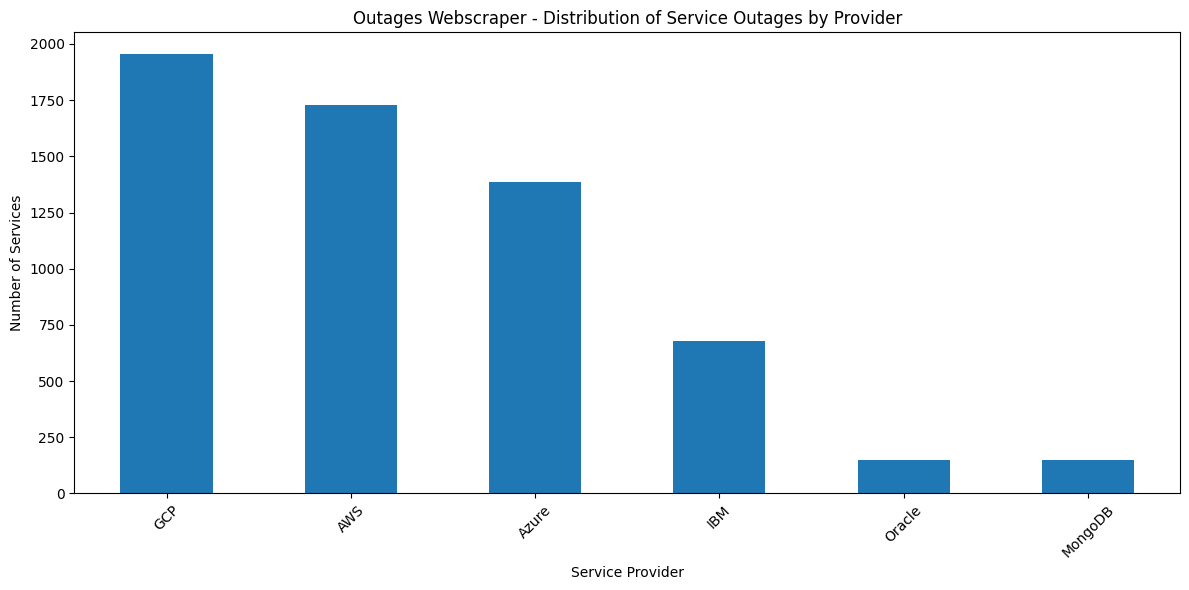

In [18]:
# 5. Outages Webscraper - Service Provider Distribution:
df = df_outages_dedup
plt.figure(figsize=(12, 6))
df['cloud_provider'].value_counts().plot(kind='bar')
plt.title('Outages Webscraper - Distribution of Service Outages by Provider')
plt.xlabel('Service Provider')
plt.ylabel('Number of Services')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

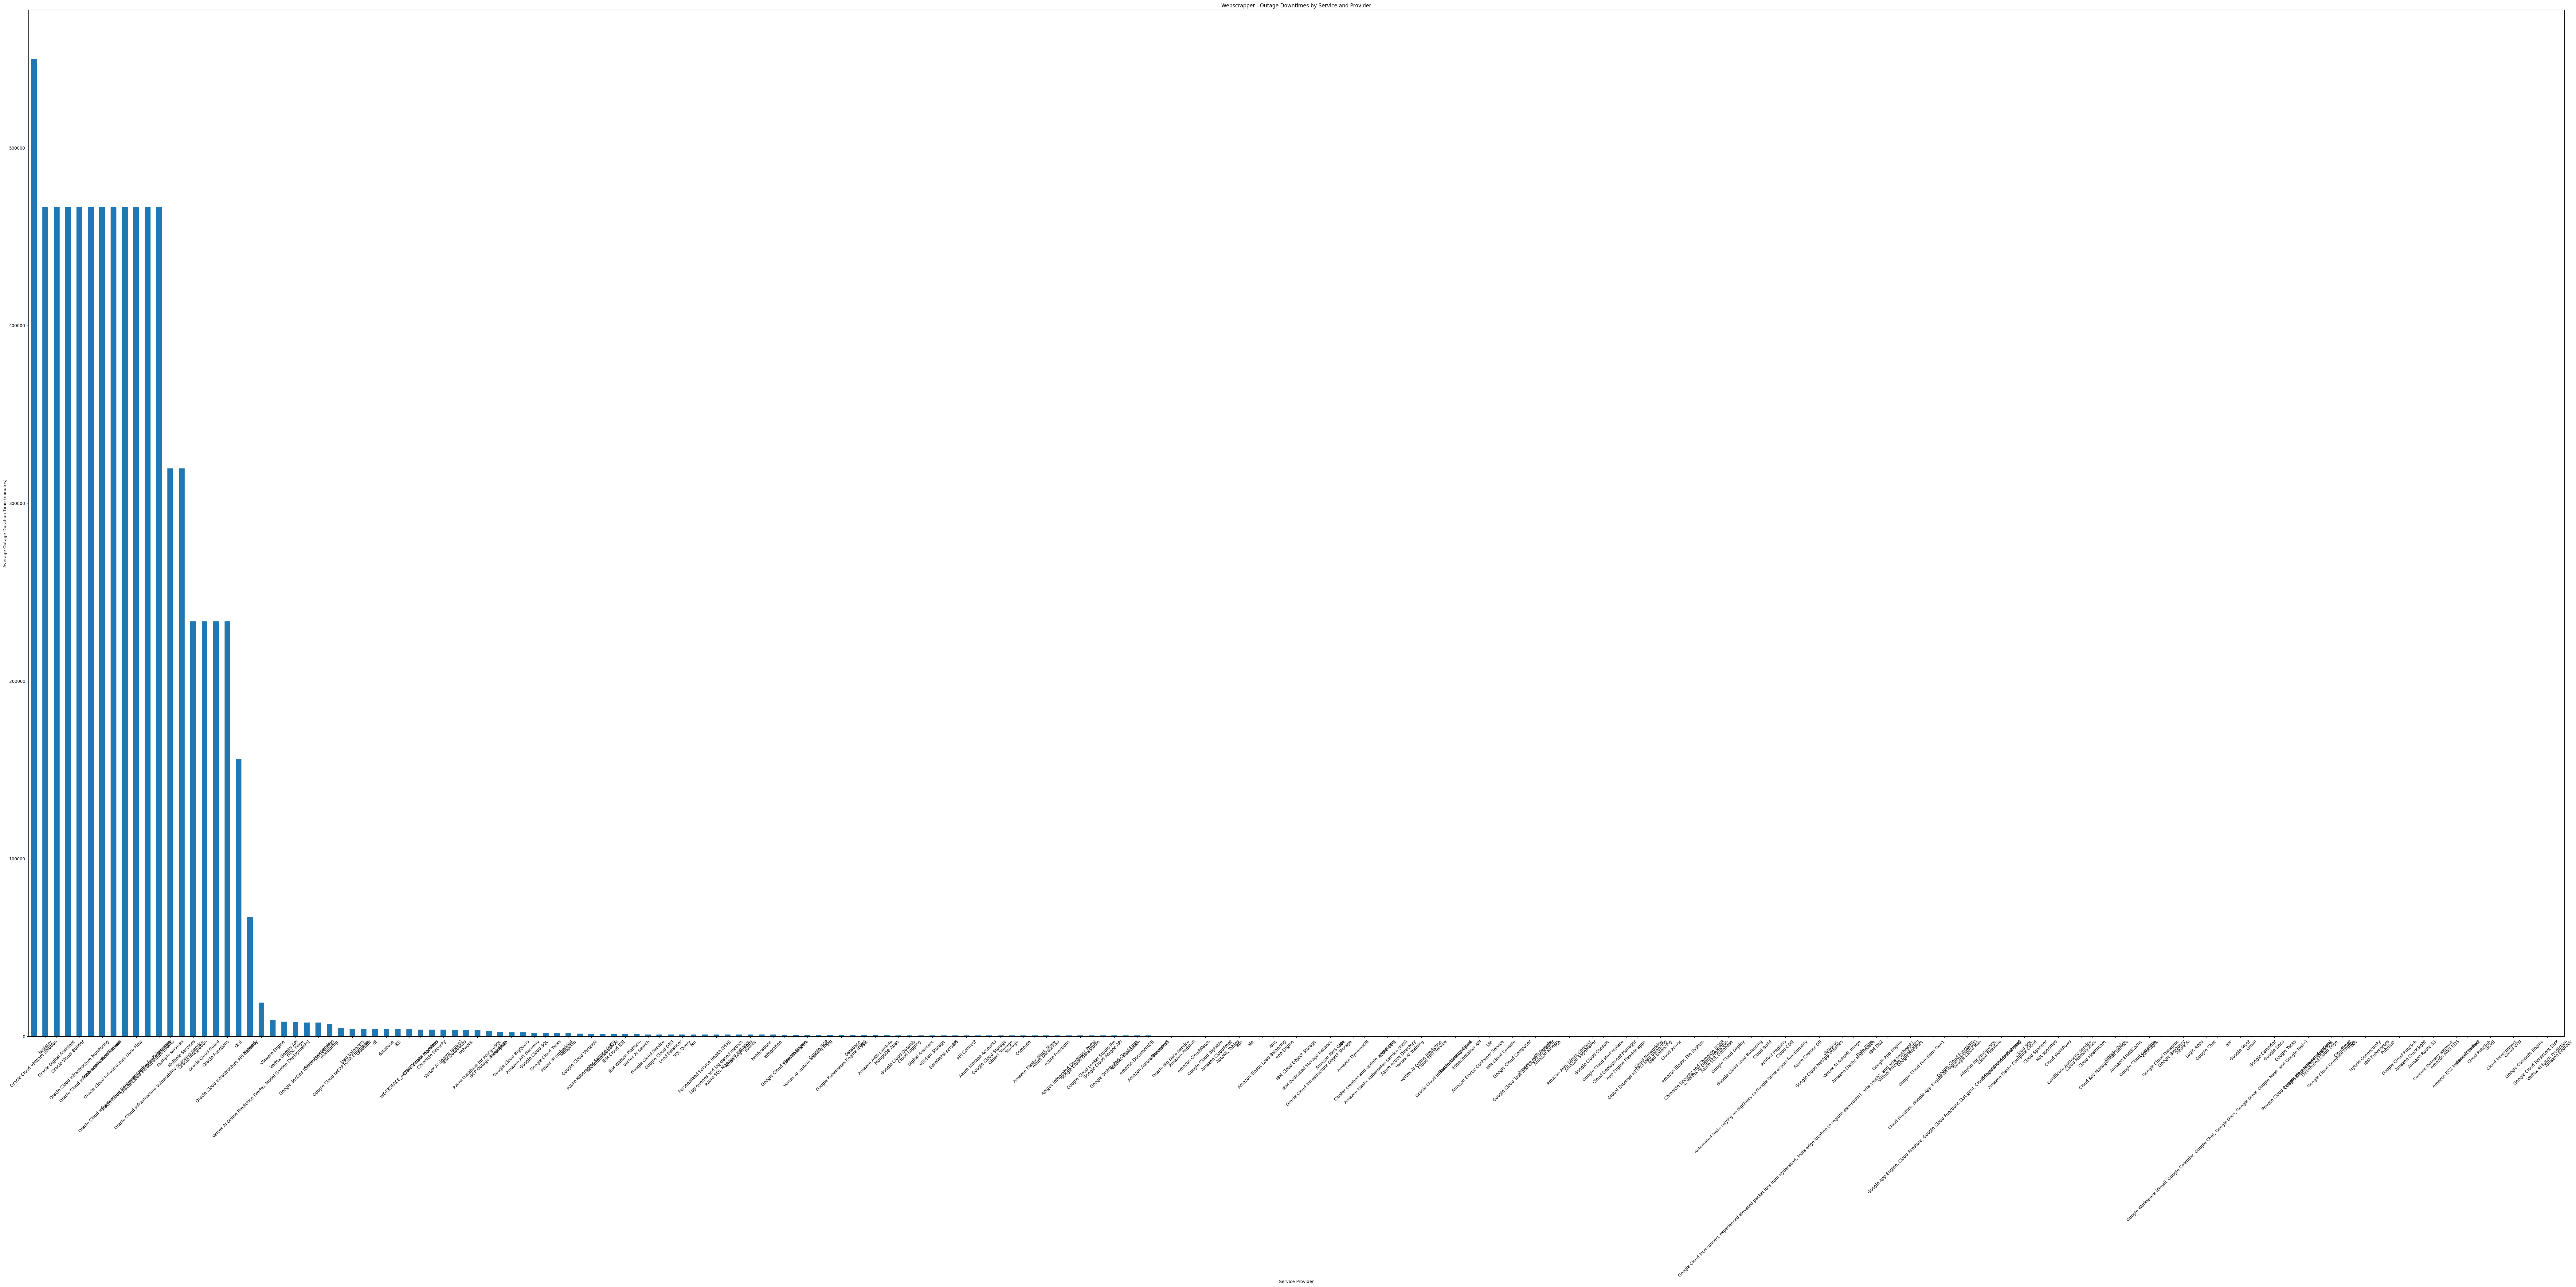

<Figure size 640x480 with 0 Axes>

In [19]:
# 6. Webscrapper - Outage Downtimes by Service and Provider:
plt.figure(figsize=(84, 42))
df.groupby('cloud_service')['duration_minutes'].mean().sort_values(ascending=False).plot(kind='bar')
plt.title('Webscrapper - Outage Downtimes by Service and Provider')
plt.xlabel('Service Provider')
plt.ylabel('Average Outage Duration Time (minutes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.savefig('Webscrapper_-_Outage_Downtimes_by_Service_and_Provider-plot.png',dpi=300)

In [20]:
print("done!")

done!


In [21]:
exit()